<a href="https://colab.research.google.com/github/kirti73/BIS_LAB/blob/main/1BF24CS140_LAB1_GA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Pseudocode: Genetic Algorithm for Dynamic Load Balancing

```text
1. Initialize Parameters:
   - Set Population Size, Max Generations, Crossover Rate, Mutation Rate.
   - Define list of Tasks with execution times and list of Virtual Machines (VMs) with capacities.

2. Initialize Population:
   - Generate a population of chromosomes.
   - Each chromosome is an array of size equal to the number of tasks, where index represents the task and value represents the assigned VM ID.

3. Evaluate Fitness:
   - For each chromosome, calculate the load (execution time / capacity) of each VM.
   - Define Makespan as the maximum completion time among all VMs.
   - Fitness = 1.0 / Makespan (lower makespan gives higher fitness).

4. Loop until termination condition (e.g., Max Generations reached):
   a. Selection:
      - Select parent chromosomes using Roulette Wheel or Tournament selection.
   b. Crossover:
      - Combine parents using crossover (e.g., single-point crossover) to create offspring.
   c. Mutation:
      - Apply mutation to randomly reassign a task to a different VM with a small probability.
   d. Replacement:
      - Form a new population using elitism (keeping the best chromosome) and offspring.
   e. Track:
      - Record the best (minimum) makespan found so far.

5. Output:
   - Return the chromosome with the best allocation schedule and its makespan.
```

### Main Functions: GA Load Balancing (High-Level Pseudocode)

```text
function INITIALIZE_POPULATION(PopSize, NumTasks, NumVMs):
    // Generate random allocations of tasks to VMs
    return ArrayOfChromosomes

function CALCULATE_FITNESS(Chromosome):
    // Measure the workload balance of this task allocation
    Makespan = Maximum_Completion_Time_Among_All_VMs(Chromosome)
    return 1.0 / Makespan

function CROSSOVER(Parent1, Parent2):
    // Combine allocation strategies of two parents
    return Offspring1, Offspring2

function MUTATE(Chromosome):
    // Randomly reassign some tasks to different VMs to explore new solutions
    return MutatedChromosome

function RUN_GENETIC_ALGORITHM():
    Population = INITIALIZE_POPULATION()
    while Generation < MaxGenerations:
        Fitnesses = Evaluate all chromosomes using CALCULATE_FITNESS()
        Parents = Select fittest individuals from Population
        Children = CROSSOVER(Parents)
        MutatedChildren = MUTATE(Children)
        Population = KeepBest(Population) + MutatedChildren
    return FittestChromosome
```

### Detailed Pseudocode: Selection & Iteration Functions

```text
function SELECT_PARENTS(Population, Fitnesses):
    // 1. Calculate cumulative probability distribution
    TotalFitness = Sum of all values in Fitnesses
    Probabilities = []
    for each Fitness in Fitnesses:
        Probabilities.add(Fitness / TotalFitness)
        
    // 2. Select two distinct parents using Roulette Wheel (fitness-proportionate selection)
    Parent1 = Randomly choose individual from Population based on Probabilities
    Parent2 = Randomly choose individual from Population based on Probabilities (excluding Parent1)
    
    return Parent1, Parent2


function RUN_GENETIC_ALGORITHM(PopSize, Generations, CrossoverRate, MutationRate):
    // 1. Setup phase
    Population = INITIALIZE_POPULATION(PopSize)
    BestHistory = []
    
    // 2. Main Evolution Loop
    for Generation from 1 to Generations:
        Fitnesses = Evaluate all chromosomes using CALCULATE_FITNESS()
        
        // Preserve elitism
        BestIndividual = Individual with Max(Fitnesses)
        NextGeneration = [BestIndividual]
        
        // 3. Reproduction step
        while Size(NextGeneration) < PopSize:
            Parent1, Parent2 = SELECT_PARENTS(Population, Fitnesses)
            
            Child1, Child2 = CROSSOVER(Parent1, Parent2, CrossoverRate)
            
            Child1 = MUTATE(Child1, MutationRate)
            Child2 = MUTATE(Child2, MutationRate)
            
            NextGeneration.add(Child1)
            if Size(NextGeneration) < PopSize:
                NextGeneration.add(Child2)
                
        Population = NextGeneration
        BestHistory.add(Fitness of BestIndividual)
        
    // 4. Return optimal solution
    BestFinalIndividual = Individual with Max(Fitnesses) in final Population
    return BestFinalIndividual, BestHistory
```

Optimal Task Assignment to VMs: [3 3 2 4 4 2 1 2 2 4 2 0 0 1 1 1 0 3 2 2]
Optimized Minimum Makespan: 8.12 seconds


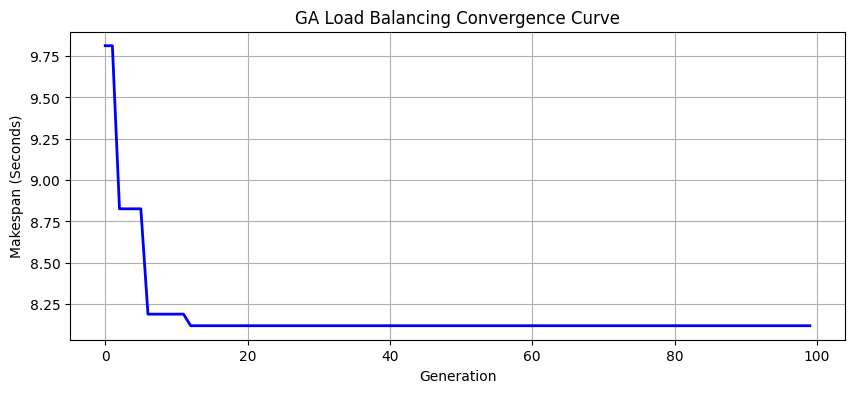

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define Problem Instance ---
NUM_TASKS = 20
NUM_VMS = 5

# Random tasks (execution requirements in Million Instructions, MI)
np.random.seed(42)
task_sizes = np.random.randint(50, 500, size=NUM_TASKS)
# VM capacities (in Million Instructions Per Second, MIPS)
vm_capacities = np.array([100, 150, 200, 120, 80])

# --- 2. GA Parameters ---
POP_SIZE = 50
GENERATIONS = 100
CROSSOVER_RATE = 0.8
MUTATION_RATE = 0.1

# --- 3. Genetic Algorithm Helper Functions ---
def init_population(pop_size, num_tasks, num_vms):
    # Each chromosome is an array of length NUM_TASKS containing VM allocations (0 to NUM_VMS-1)
    return [np.random.randint(0, num_vms, size=num_tasks) for _ in range(pop_size)]

def calculate_makespan(chromosome):
    """Calculates the makespan (maximum completion time among all VMs) for a given schedule."""
    vm_times = np.zeros(NUM_VMS)
    for task_idx, vm_idx in enumerate(chromosome):
        # Execution time = Task Size / VM Capacity
        vm_times[vm_idx] += task_sizes[task_idx] / vm_capacities[vm_idx]
    return np.max(vm_times)

def calculate_fitness(chromosome):
    """Fitness is inversely proportional to makespan."""
    makespan = calculate_makespan(chromosome)
    return 1.0 / (makespan + 1e-6)

def select_parents(population, fitnesses):
    """Roulette wheel selection"""
    total_fit = sum(fitnesses)
    probs = [f / total_fit for f in fitnesses]
    idx1, idx2 = np.random.choice(len(population), size=2, replace=False, p=probs)
    return population[idx1], population[idx2]

def crossover(parent1, parent2):
    if random.random() < CROSSOVER_RATE:
        point = random.randint(1, NUM_TASKS - 1)
        child1 = np.concatenate((parent1[:point], parent2[point:]))
        child2 = np.concatenate((parent2[:point], parent1[point:]))
        return child1, child2
    return parent1.copy(), parent2.copy()

def mutate(chromosome):
    for i in range(len(chromosome)):
        if random.random() < MUTATION_RATE:
            chromosome[i] = random.randint(0, NUM_VMS - 1)
    return chromosome

# --- 4. GA Main Loop ---
population = init_population(POP_SIZE, NUM_TASKS, NUM_VMS)
best_makespan_history = []

for generation in range(GENERATIONS):
    fitnesses = [calculate_fitness(chrom) for chrom in population]
    makespans = [calculate_makespan(chrom) for chrom in population]

    best_idx = np.argmin(makespans)
    best_makespan_history.append(makespans[best_idx])

    new_pop = [population[best_idx].copy()] # Elitism

    while len(new_pop) < POP_SIZE:
        p1, p2 = select_parents(population, fitnesses)
        c1, c2 = crossover(p1, p2)
        new_pop.append(mutate(c1))
        if len(new_pop) < POP_SIZE:
            new_pop.append(mutate(c2))

    population = new_pop

# --- 5. Output and Visualization ---
best_idx = np.argmin([calculate_makespan(c) for c in population])
best_solution = population[best_idx]

print(f"Optimal Task Assignment to VMs: {best_solution}")
print(f"Optimized Minimum Makespan: {calculate_makespan(best_solution):.2f} seconds")

# Plot Convergence Curve
plt.figure(figsize=(10, 4))
plt.plot(best_makespan_history, color='blue', linewidth=2)
plt.title("GA Load Balancing Convergence Curve")
plt.xlabel("Generation")
plt.ylabel("Makespan (Seconds)")
plt.grid(True)
plt.show()

In [ ]:
# hello

In [ ]:
''' hello'''

' hello'

In [ ]:
//retry

SyntaxError: invalid syntax (659535961.py, line 1)

In [ ]:
"""googoogaagaa"""


'googoogaagaa'